## **K-Means** (corrected edition)

Changes with respect to `K-Means_original.ipynb`: (1) a reusable `lloyd()` function replaces three copies of the same loop; (2) empty clusters are handled instead of silently producing `NaN`; (3) the misleading comment *"5 is one of the best seeds"* is replaced by an experiment that shows how strongly the result depends on the seed; (4) the K-means++ sampling loop (`if r < p`) could occasionally append no centroid -- it now uses `rng.choice(p=...)`; (5) the plotting loop in the last cell had the `plt.show()` indented inside the `for` loop; (6) the elbow curve is computed with several restarts per K and complemented by the silhouette score; (7) the empty last cell was removed.

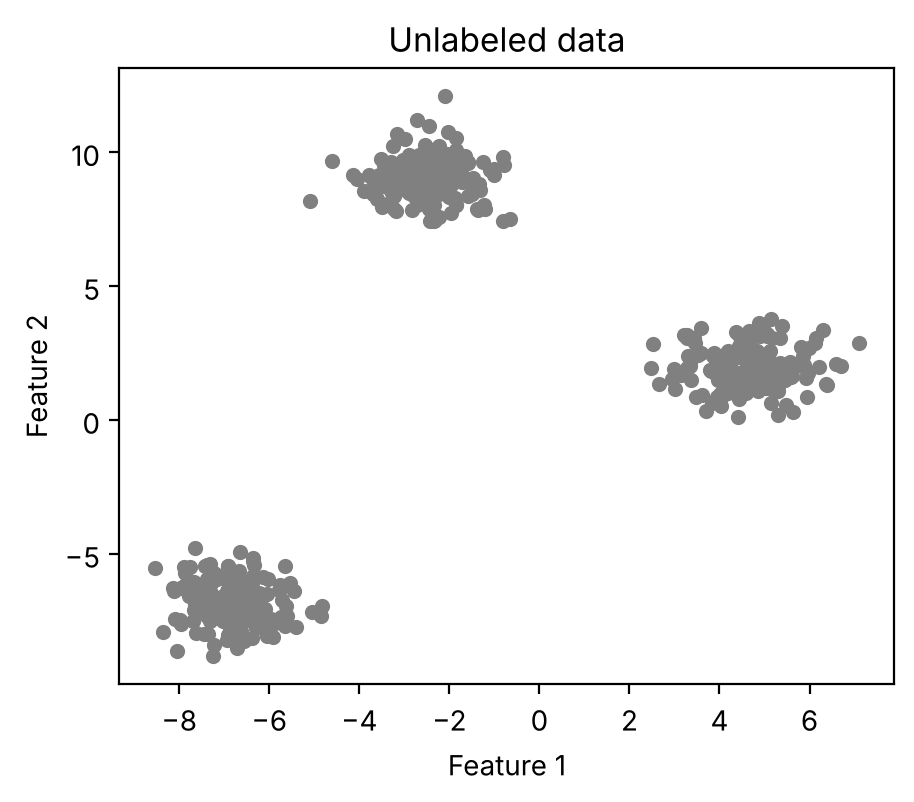

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X, y_true = make_blobs(n_samples=500, centers=3, cluster_std=0.8, random_state=42)
plt.figure(figsize=(5, 4)); plt.scatter(X[:, 0], X[:, 1], s=20, c='gray')
plt.title("Unlabeled data"); plt.xlabel("Feature 1"); plt.ylabel("Feature 2"); plt.show()

### 1. Lloyd's algorithm from scratch

Objective: $J=\sum_i \lVert x_i-\mu_{c_i}\rVert^2$ (sum of **squared** distances). Each assignment step and each update step can only decrease $J$, so the algorithm stops after finitely many iterations -- but only in a *local* minimum.

J per iteration: [33710.87  3257.44   611.62]


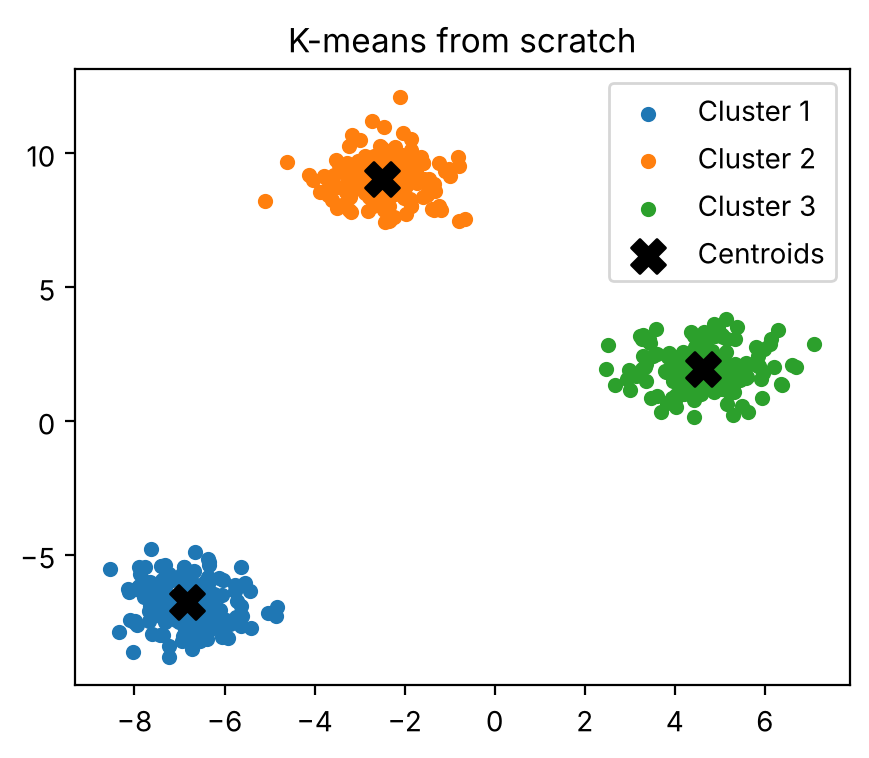

In [2]:
def sq_dists(X, C):
    return ((X[:, None, :] - C[None, :, :]) ** 2).sum(axis=2)       # (n, K)

def lloyd(X, centroids, max_iters=100):
    centroids = centroids.copy()
    history = []
    for it in range(max_iters):
        D = sq_dists(X, centroids)
        labels = D.argmin(axis=1)
        history.append(D[np.arange(len(X)), labels].sum())          # J for the current centroids
        new = centroids.copy()
        for k in range(len(centroids)):
            if (labels == k).any():
                new[k] = X[labels == k].mean(axis=0)
            else:                                                   # empty cluster: re-seed at the worst-fitted point
                new[k] = X[D[np.arange(len(X)), labels].argmax()]
        if np.allclose(new, centroids):
            break
        centroids = new
    return centroids, labels, history

def random_init(X, K, rng):
    return X[rng.choice(len(X), K, replace=False)].copy()           # replace=False: K distinct points

K = 3
c, lab, hist = lloyd(X, random_init(X, K, np.random.default_rng(11)))
print("J per iteration:", np.round(hist, 2))
assert all(a >= b - 1e-9 for a, b in zip(hist, hist[1:])), "J must not increase"

plt.figure(figsize=(5, 4))
for k in range(K):
    plt.scatter(X[lab == k, 0], X[lab == k, 1], s=20, label=f"Cluster {k+1}")
plt.scatter(c[:, 0], c[:, 1], s=150, c='black', marker='X', label='Centroids')
plt.title("K-means from scratch"); plt.legend(); plt.show()

### 2. Initialisation matters: there is no "best seed"

The original comment claimed seed 5 was among the best. Whether a seed is good depends on the data and on the number of clusters; we measure it instead of guessing.

best J = 611.6, worst J = 17811.2; seeds that end in a bad local minimum: 8 of 30


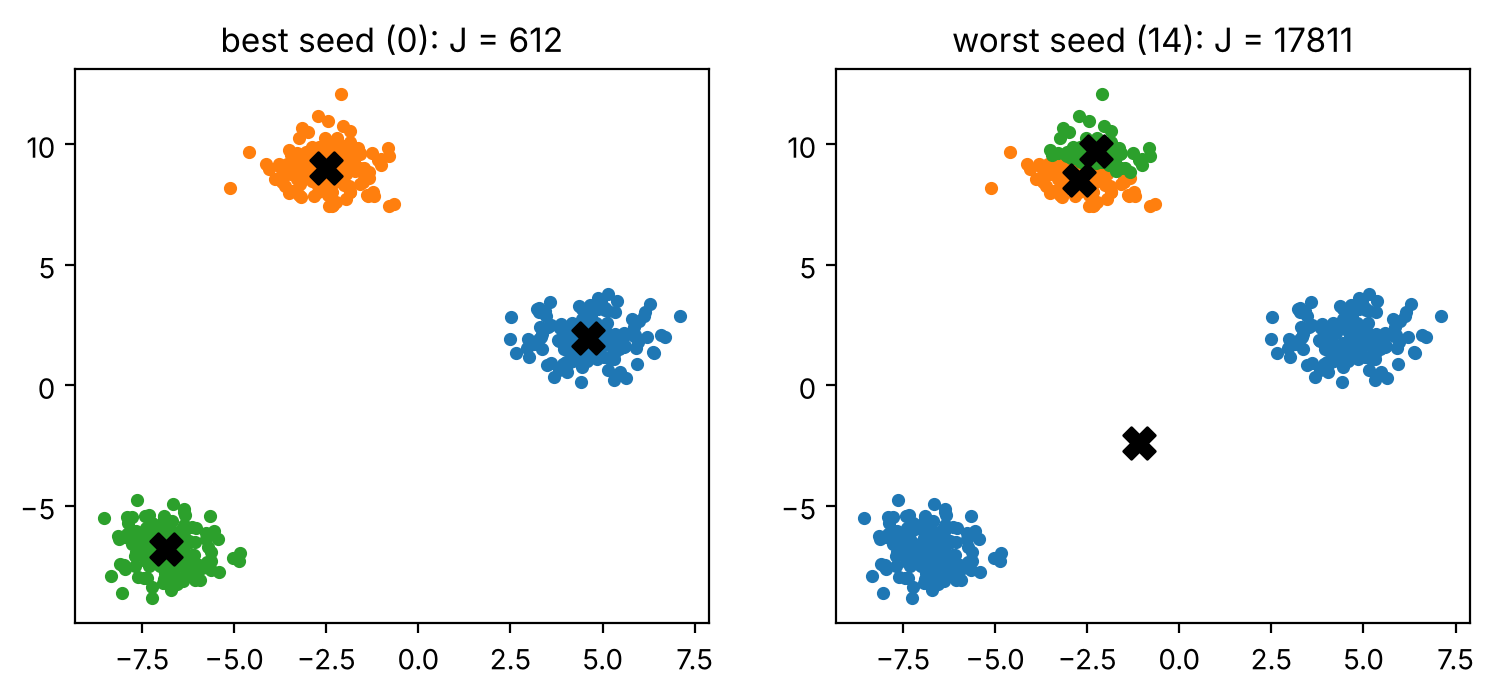

In [3]:
Js = []
for seed in range(30):
    _, _, h = lloyd(X, random_init(X, K, np.random.default_rng(seed)))
    Js.append(h[-1])
Js = np.array(Js)
print(f"best J = {Js.min():.1f}, worst J = {Js.max():.1f}; seeds that end in a bad local minimum: {(Js > 1.5*Js.min()).sum()} of 30")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
for a, seed, title in [(ax[0], int(Js.argmin()), "best seed"), (ax[1], int(Js.argmax()), "worst seed")]:
    c_, l_, h_ = lloyd(X, random_init(X, K, np.random.default_rng(seed)))
    for k in range(K): a.scatter(X[l_ == k, 0], X[l_ == k, 1], s=14)
    a.scatter(c_[:, 0], c_[:, 1], s=130, c='black', marker='X'); a.set_title(f"{title} ({seed}): J = {h_[-1]:.0f}")
plt.show()

In [4]:
sk = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=0).fit(X)
print("scikit-learn (k-means++, 10 restarts): inertia =", round(sk.inertia_, 2))
print("ours, best of the 30 seeds             : J       =", round(Js.min(), 2))

scikit-learn (k-means++, 10 restarts): inertia = 611.62
ours, best of the 30 seeds             : J       = 611.62


## **K-Means++**

Seeding: the first centre is uniform; every next centre is drawn with probability $D(x)^2/\sum_{x'}D(x')^2$, where $D(x)$ is the distance to the nearest centre already chosen.

In [5]:
def kmeanspp_init(X, K, rng):
    n = len(X)
    centroids = [X[rng.integers(n)]]
    d2 = sq_dists(X, np.array(centroids)).min(axis=1)
    for _ in range(1, K):
        idx = rng.choice(n, p=d2 / d2.sum())                        # always returns an index
        centroids.append(X[idx])
        d2 = np.minimum(d2, sq_dists(X, X[idx][None, :])[:, 0])
    return np.array(centroids)

Jpp = np.array([lloyd(X, kmeanspp_init(X, K, np.random.default_rng(s)))[2][-1] for s in range(30)])
print(f"random init : median J = {np.median(Js):.1f}, worst = {Js.max():.1f}")
print(f"k-means++   : median J = {np.median(Jpp):.1f}, worst = {Jpp.max():.1f}")

random init : median J = 611.6, worst = 17811.2
k-means++   : median J = 611.6, worst = 8979.9


## **Choosing the right K**

A harder data set: five blobs with different standard deviations.

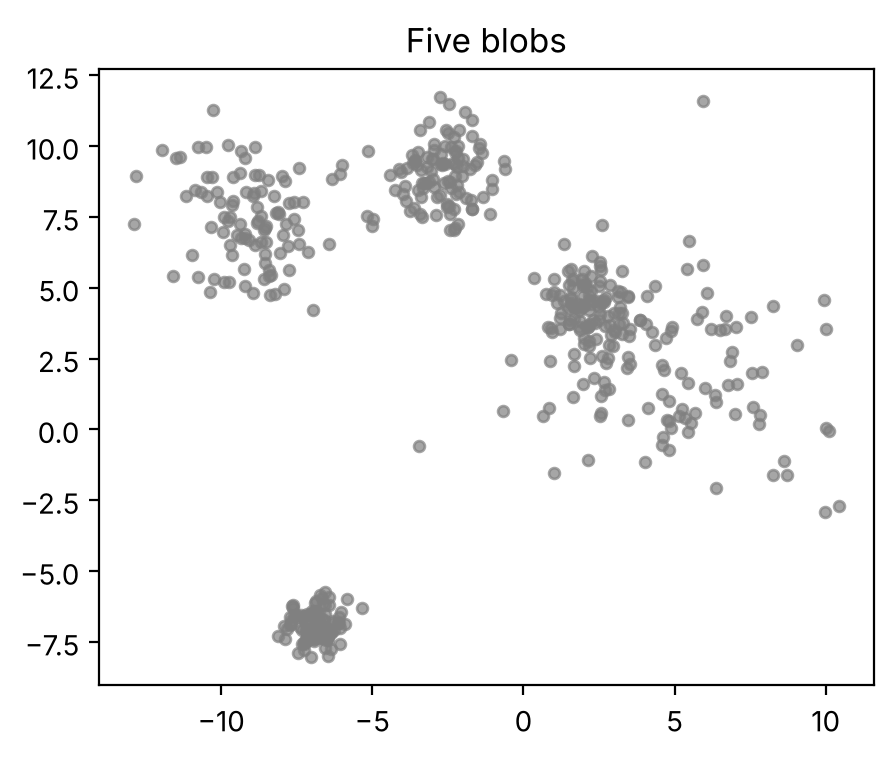

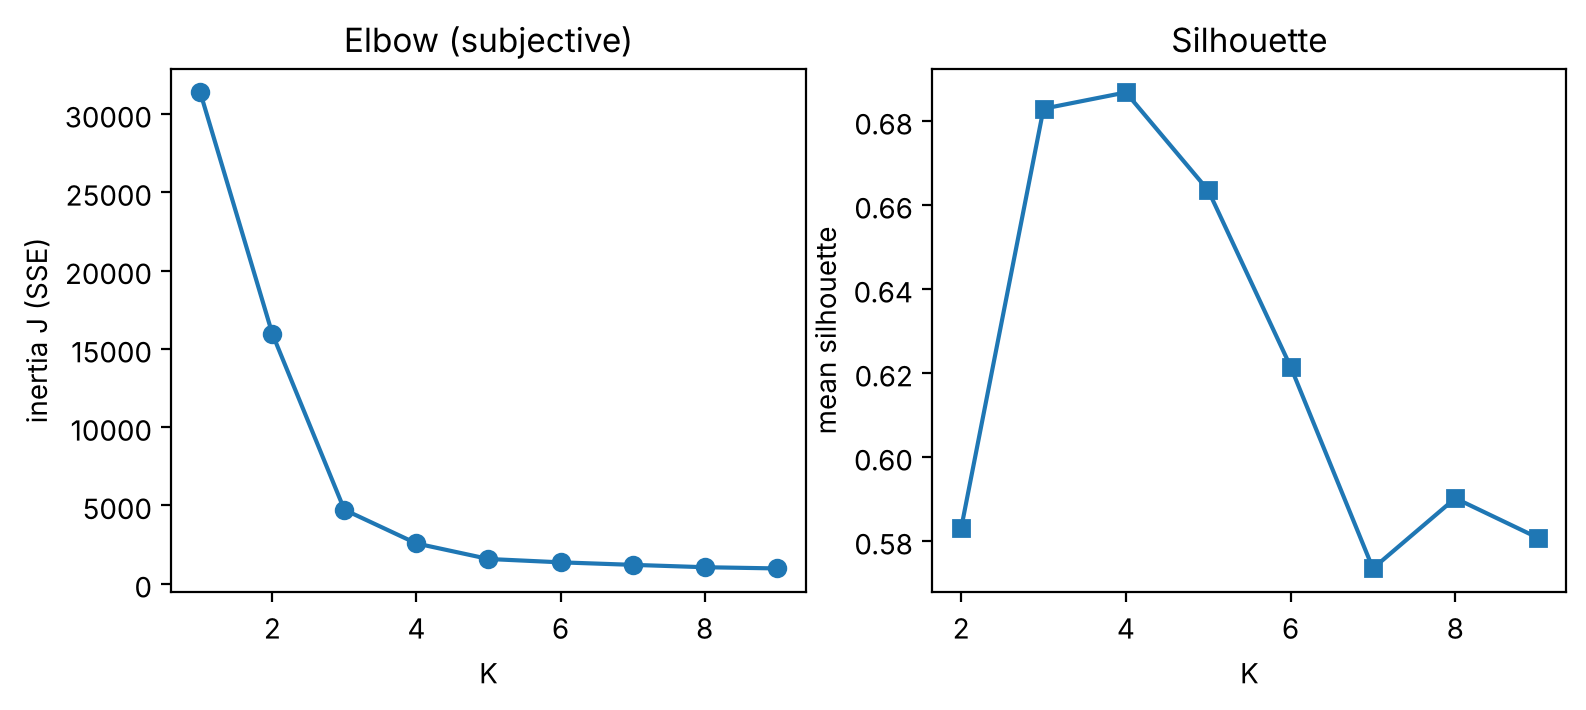

silhouette suggests K = 4 (the data were generated with 5 blobs of unequal spread)


In [6]:
X, _ = make_blobs(n_samples=500, centers=5, cluster_std=[1.0, 2.5, 0.5, 1.5, 0.8], random_state=42)
plt.figure(figsize=(5, 4)); plt.scatter(X[:, 0], X[:, 1], c='gray', s=15, alpha=0.7); plt.title("Five blobs"); plt.show()

def kmeanspp(X, K, n_init=10, seed=0):
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(n_init):                                         # restarts: keep the run with the smallest J
        c, l, h = lloyd(X, kmeanspp_init(X, K, rng))
        if best is None or h[-1] < best[2]:
            best = (c, l, h[-1])
    return best

Ks = range(1, 10)
costs = [kmeanspp(X, k)[2] for k in Ks]
sils = [silhouette_score(X, kmeanspp(X, k)[1]) for k in Ks if k >= 2]

fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].plot(list(Ks), costs, 'o-'); ax[0].set_xlabel("K"); ax[0].set_ylabel("inertia J (SSE)"); ax[0].set_title("Elbow (subjective)")
ax[1].plot(list(range(2, 10)), sils, 's-'); ax[1].set_xlabel("K"); ax[1].set_ylabel("mean silhouette"); ax[1].set_title("Silhouette")
plt.show()
print("silhouette suggests K =", 2 + int(np.argmax(sils)), "(the data were generated with 5 blobs of unequal spread)")

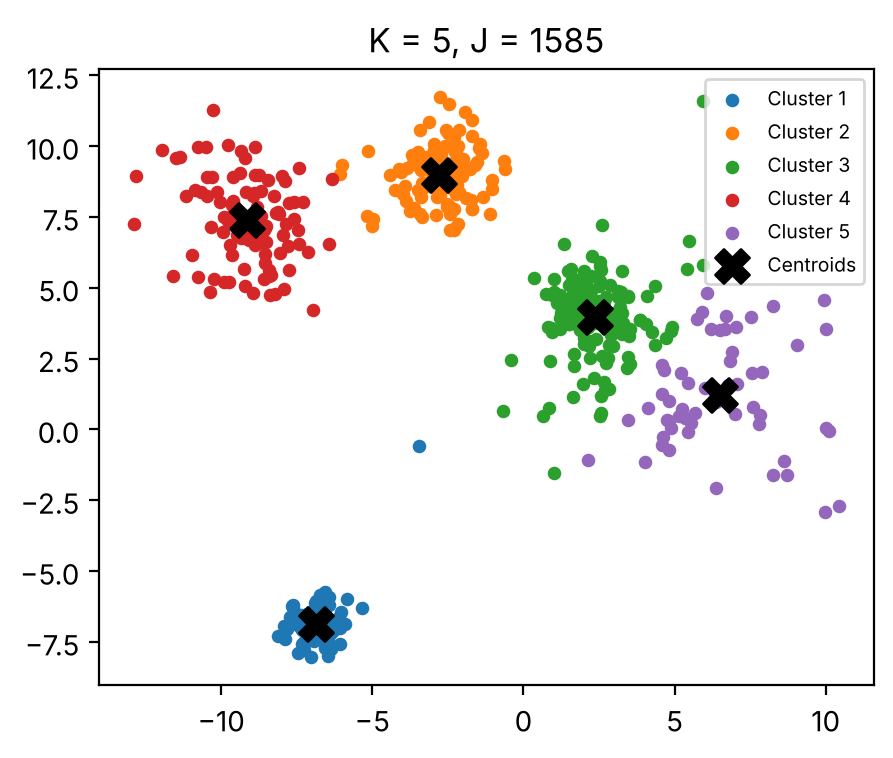

In [7]:
best_K = 5
c, l, J = kmeanspp(X, best_K)
plt.figure(figsize=(5, 4))
for k in range(best_K):
    plt.scatter(X[l == k, 0], X[l == k, 1], s=15, label=f"Cluster {k+1}")
plt.scatter(c[:, 0], c[:, 1], c='black', s=150, marker='X', label='Centroids')   # drawn once, outside the loop
plt.title(f"K = {best_K}, J = {J:.0f}"); plt.legend(fontsize=7); plt.show()